<a href="https://colab.research.google.com/github/projet-virage/ActiveTransportation/blob/main/SocialInteraction_Relocation_Scenarios_10_20_and_30%25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install mesa
!pip install osmnx
!pip install optuna
!pip install gower

In [2]:
from mesa import Model, Agent
from mesa.datacollection import DataCollector
from mesa.time import Schedule
import os

import geopandas as gpd
import networkx as nx
import osmnx
import numpy as np
import random
from shapely.geometry import Point
from scipy.spatial import KDTree
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import differential_evolution
import pandas as pd
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import time
import optuna
import math
from scipy.stats import truncnorm
import gower
from pathlib import Path
from collections import defaultdict

# Importing spatial data and preprocessing them

In [3]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    # Running outside of Google Colab
    pass

Mounted at /content/drive


In [4]:
data_path = os.environ.get("DATA_FOLDER", "/content/drive/MyDrive/Transportation_UrbanHealth")
# Importing Census Data
df = pd.read_csv(os.path.join(data_path, "Census2021_EducationIncluded.csv")).iloc[1:,:]
gender = pd.read_csv(os.path.join(data_path, "Gender.csv")).drop(columns=['Population']).dropna().reset_index(drop=True)

# Importing Spatial Data
MTL_DA = gpd.read_file(os.path.join(data_path, "DA_MTL_MTM.shp"))[['UID_12','geometry']].rename(columns={'UID_12':'DA_name'})
residential = gpd.read_file(os.path.join(data_path, "Residential_MTM.shp"))
workplaces = gpd.read_file(os.path.join(data_path, "workplaces.shp"))
stm = gpd.read_file(os.path.join(data_path, "STM_MTM.shp"))
Bikelanes = gpd.read_file(os.path.join(data_path, "VQ_bikelanes.shp"))

# Nodes and Edges for the networks
Netnodes = gpd.read_file(os.path.join(data_path, "Nodes.shp"))
Netedges_car = gpd.read_file(os.path.join(data_path, "Edges_car.shp")).set_index(['u', 'v', 'key'])
Netedges_walk = gpd.read_file(os.path.join(data_path, "Edges_walk.shp")).set_index(['u', 'v', 'key'])
Netedges_bike = gpd.read_file(os.path.join(data_path, "Edges_bike.shp")).set_index(['u', 'v', 'key'])
Netedges_transit = gpd.read_file(os.path.join(data_path, "Edges_transit.shp")).set_index(['u', 'v', 'key'])

In [5]:
df_census_data = df.rename(columns={
    "COL0": "DA_name",
    "COL1": "Education_no_certificate",
    "COL2": "Education_HighSchool",
    "COL3": "Education_BelowBachelor",
    "COL4": "Education_Bachelor_and_above",
    "COL5": "Car",
    "COL6": "Transit",
    "COL7": "Walk",
    "COL8": "Bike",
    "COL9": "commute_time_less_15",
    "COL10": "commute_time_15_30",
    "COL11": "commute_time_30_45",
    "COL12": "commute_time_45_60",
    "COL13": "commute_time_more_60",
    "COL14": "Male",
    "COL15": "Female",
})

df_census_data.dropna(inplace=True)

df_census_data['All_modes'] = df_census_data['Car'] + df_census_data['Transit'] + df_census_data['Walk'] + df_census_data['Bike']

df_census_data["All_Education_Categories"] = df_census_data[["Education_no_certificate","Education_HighSchool", "Education_BelowBachelor","Education_Bachelor_and_above"]].sum(axis= 1)
df_census_data = df_census_data.loc[df_census_data['All_Education_Categories'] != 0].copy()
# Percentage of each group
df_census_data[["Education_no_certificate","Education_HighSchool", "Education_BelowBachelor","Education_Bachelor_and_above"]]= df_census_data[["Education_no_certificate","Education_HighSchool", "Education_BelowBachelor","Education_Bachelor_and_above"]].apply(lambda x: x/df_census_data["All_Education_Categories"])


df_census_data["Education_no_certificate"] = 1 - df_census_data[["Education_HighSchool", "Education_BelowBachelor","Education_Bachelor_and_above"]].sum(axis= 1)


df_census_data['commute_time_15_30'] = df_census_data['commute_time_less_15'] + df_census_data['commute_time_15_30']
df_census_data['Total_commuters'] = df_census_data['commute_time_15_30'] + df_census_data['commute_time_30_45'] + df_census_data['commute_time_45_60'] + df_census_data['commute_time_more_60']

df_census_data = df_census_data.loc[df_census_data['Total_commuters'] != 0].copy()

df_census_data[['commute_time_15_30', 'commute_time_30_45', 'commute_time_45_60', 'commute_time_more_60']] = df_census_data[['commute_time_15_30', 'commute_time_30_45', 'commute_time_45_60', 'commute_time_more_60']].apply(lambda x: x/df_census_data["Total_commuters"])

df_census_data['commute_time_15_30'] = 1 - (df_census_data['commute_time_30_45'] + df_census_data['commute_time_45_60'] + df_census_data['commute_time_more_60'])
df_census_data[['Male',	'Female']] = df_census_data[['Male',	'Female']].apply(lambda x: x/(df_census_data['Male'] + df_census_data['Female']))
df_census_data['Female'] = 1 - df_census_data['Male']
df_census_data.drop(columns=['commute_time_less_15', 'Total_commuters', "All_Education_Categories"], inplace=True)


# Merging the cencus data with the DA
montreal_da =pd.merge(MTL_DA, df_census_data, on="DA_name", how= 'right').copy()

# Creating Networks

In [6]:
nodex = Netnodes.join(Netnodes.get_coordinates()).set_index('nodeid')[['x', 'y', 'geometry']]

# Load network
netx_car = osmnx.graph_from_gdfs(nodex, Netedges_car)
netx_walk = osmnx.graph_from_gdfs(nodex, Netedges_walk)
netx_bike = osmnx.graph_from_gdfs(nodex, Netedges_bike)
netx_transit = osmnx.graph_from_gdfs(nodex, Netedges_transit)

# Plotting Network

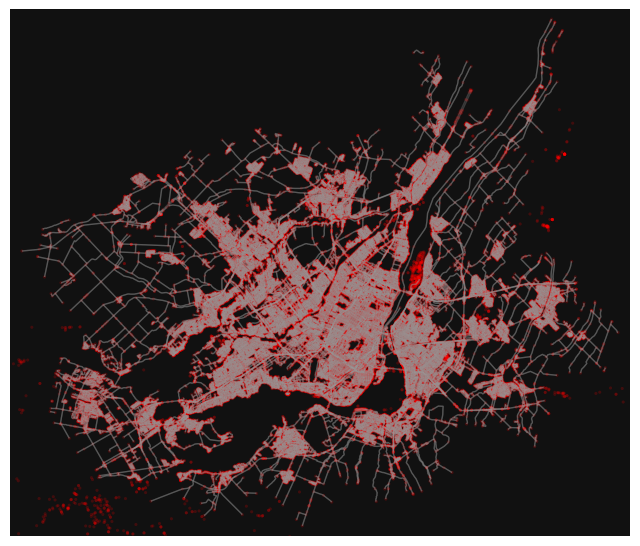

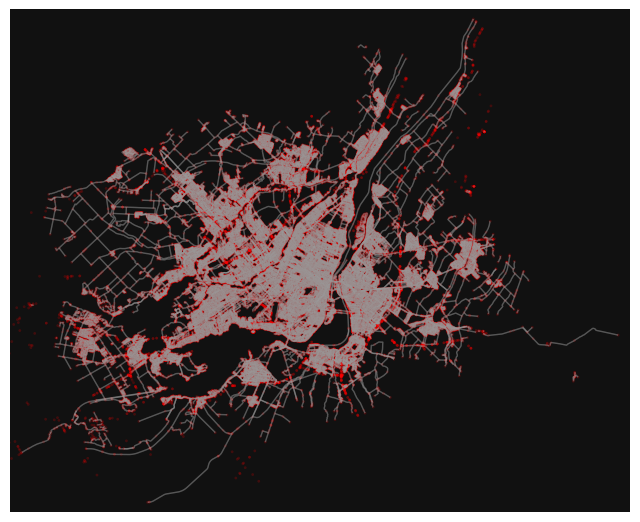

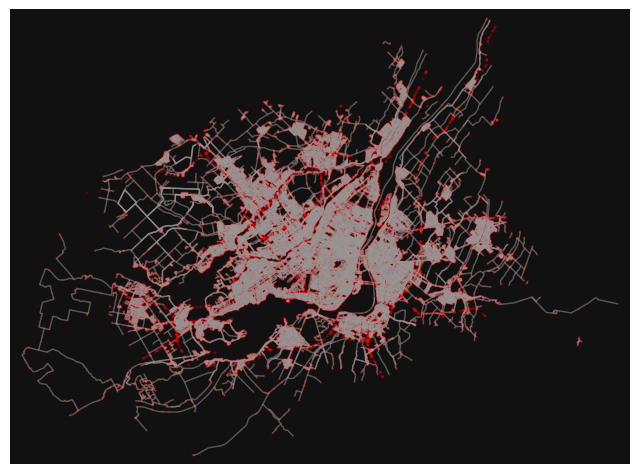

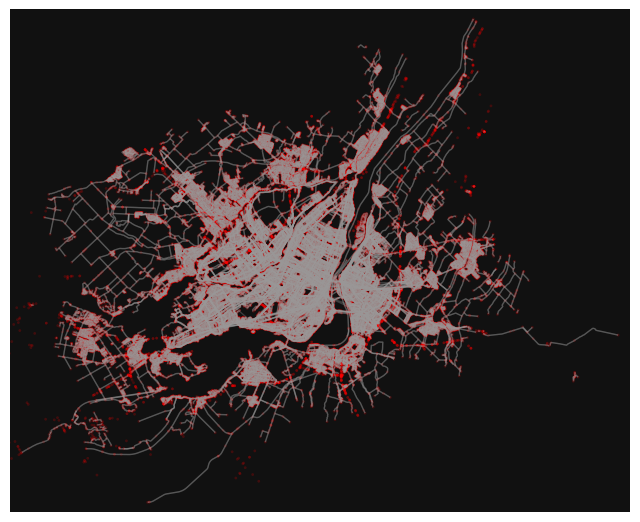

In [ ]:
# Car network
fig, ax = osmnx.plot.plot_graph(netx_car, edge_alpha=.3, node_color="r", node_size=5, node_zorder=0, node_alpha=.2)

# Walk network
fig, ax = osmnx.plot.plot_graph(netx_walk, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Bike network
fig, ax = osmnx.plot.plot_graph(netx_bike, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Transit network
fig, ax = osmnx.plot.plot_graph(netx_transit, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Model development

In [7]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [8]:
# The main function
class TransportModel(Model):

  def __init__(self, n_rep, DA_MTL, Res, Net_car, Net_walk, Net_bike, Net_transit, Wrk_N, STM_N, bikelanes, interaction_radius=1000, min_peers=5,max_peers=10):
    super().__init__()
    self.agent_list = []
    self.Each_agent_represents = n_rep
    self.montreal_da = DA_MTL.copy()
    self.residential = Res.copy()
    self.betas = None
    self.bikelanes = bikelanes.copy()
    self.bikelane_sindex = self.bikelanes.sindex

    self.Gc = Net_car
    self.Gw = Net_walk
    self.Gb = Net_bike
    self.Gstm = Net_transit

    self.workplaces = Wrk_N.copy()
    self.stms = STM_N.copy()

    self.car_cache = {}
    self.walk_cache = {}
    self.transit_cache = {}
    self.bike_cache = {}

    self.interaction_radius = interaction_radius
    self.min_peers = min_peers
    self.max_peers = max_peers

    # Add network nodes
    self.stms['network_node'] = osmnx.distance.nearest_nodes(self.Gw, self.stms.geometry.x, self.stms.geometry.y)
    self.stm_tree = KDTree(np.column_stack([self.stms.geometry.x, self.stms.geometry.y]))
    #----------------------------------------------------------------------
    # Residential
    self.residential["res_id"] = np.arange(len(self.residential))

    x = self.residential.centroid.x.values
    y = self.residential.centroid.y.values

    self.residential["network_node"] = osmnx.distance.nearest_nodes(self.Gw, x, y)

    self.residential["x"] = x
    self.residential["y"] = y

    self.res_lookup = (self.residential.set_index("res_id")[["network_node", "x", "y"]].to_dict("index"))
    #----------------------------------------------------------------------
    # Workplaces
    self.workplaces["wrk_id"] = np.arange(len(self.workplaces))

    # Workplace coordinates
    self.workplaces["x"] = self.workplaces.geometry.x
    self.workplaces["y"] = self.workplaces.geometry.y

    xw = self.workplaces.geometry.x.values
    yw = self.workplaces.geometry.y.values

    self.workplaces["network_node"] = osmnx.distance.nearest_nodes(self.Gw, xw, yw)
    self.wrk_lookup = (self.workplaces.set_index("wrk_id")[["network_node", "x", "y"]].to_dict("index"))
    # Workplace KDTree
    self.workplace_tree = KDTree(np.column_stack([self.workplaces.geometry.x, self.workplaces.geometry.y]))
    #-----------------------------------------------------------------------------------------
    # Create agents
    self.create_agents()

    # Assigning local population density
    self.assign_local_population_density()

    # Assigning transit stop density around home
    self.assign_transit_stop_density(self.agent_list)

    # Activate agents in random order
    for agentt in tqdm(random.sample(self.agent_list, len(self.agent_list)), desc= "Agents activation"):
      agentt.step()

    self.initialize_social_network()
    self.compute_all_travel_times(self.agent_list)

    # prepare static variables and statistics once
    self.prepare_static_calibration_data()

  # --------------------------------------------------------
  def closest_candidate_node(self, G, source_node, candidate_gdf, tree):

    source_xy = (G.nodes[source_node]['x'],G.nodes[source_node]['y'])

    distance, idx = tree.query(source_xy)
    return candidate_gdf.iloc[idx]['network_node']
  # --------------------------------------------------------
  def create_agents(self):

    pbar = tqdm(self.montreal_da.iterrows(), total=len(self.montreal_da))
    for _, da in pbar:
      pbar.set_description(f"Creating agents for DA: {da['DA_name']}")

      if da['Car'] == 0 and da['Transit'] == 0 and da['Bike'] == 0 and da['Walk'] == 0:
        continue

      else:
        # Residential polygons inside this DA
        res = self.residential[self.residential.intersects(da.geometry)]
        if res.empty:
          continue


        agents_with_DAs =[]
        # Initializing Agents (age_15–64)
        num_adults = round((da['Car'] / self.Each_agent_represents)) + round((da['Transit'] / self.Each_agent_represents))+ round((da['Bike'] / self.Each_agent_represents)) + round((da['Walk'] / self.Each_agent_represents))

        male_num = round(da['Male'] * num_adults)
        female_num = num_adults - male_num

        # Male initialization
        for _ in range(male_num):

          poly = res.iloc[[np.random.randint(len(res))]]

          agent = PersonAgent(self, {
              'age': random.randint(15, 64),
              'gender': 0,
              'DA_ID': da['DA_name'],
              'education': None,
              'res_id': poly['res_id'].values[0],
              'x': poly.geometry.centroid.x.values[0],
              'y': poly.geometry.centroid.y.values[0],
              'proximity_to_bikelane': None,
              'commute_distance': None,
              'pop_dens': np.nan,
              'transit_stop_density': np.nan
              })

          self.agent_list.append(agent)
          agents_with_DAs.append(agent)

        # Female initialization
        for _ in range(female_num):
          poly = res.iloc[[np.random.randint(len(res))]]

          agent = PersonAgent(self, {
              'age': random.randint(15, 64),
              'gender': 1,
              'DA_ID': da['DA_name'],
              'education': None,
              'res_id': poly['res_id'].values[0],
              'x': poly.geometry.centroid.x.values[0],
              'y': poly.geometry.centroid.y.values[0],
              'proximity_to_bikelane': None,
              'commute_distance': None,
              'pop_dens': np.nan,
              'transit_stop_density': np.nan
          })

          self.agent_list.append(agent)
          agents_with_DAs.append(agent)

        # Calculating the number of the agents in each coomute group

        num_agents_wit_commute_time_30_45 = math.floor(da['commute_time_30_45'] * num_adults)
        num_agents_wit_commute_time_45_60 = math.floor(da['commute_time_45_60'] * num_adults)
        num_agents_wit_commute_time_more_60 = math.floor(da['commute_time_more_60'] * num_adults)
        num_agents_wit_commute_time_15_30 = num_adults - (num_agents_wit_commute_time_30_45 + num_agents_wit_commute_time_45_60 + num_agents_wit_commute_time_more_60)

        commute_categories = (
            [4000] * num_agents_wit_commute_time_15_30 +
            [8000] * num_agents_wit_commute_time_30_45 +
            [13000] * num_agents_wit_commute_time_45_60 +
            [18000] * num_agents_wit_commute_time_more_60
        )

        # Randomize which agent receives which category
        random.shuffle(commute_categories)

        for agent, category in zip(agents_with_DAs, commute_categories):
          agent.commute_distance = category


        # Calculating the number of the agents in each education category
        num_agents_with_HighSchool = math.floor(da['Education_HighSchool'] * num_adults)
        num_agents_with_BelowBachelor = math.floor(da['Education_BelowBachelor'] * num_adults)
        num_agents_with_Bachelor_and_above = math.floor(da['Education_Bachelor_and_above'] * num_adults)
        num_agents_with_no_certificate = num_adults - (num_agents_with_HighSchool + num_agents_with_BelowBachelor + num_agents_with_Bachelor_and_above)


        education_categories = (["Education_no_certificate"] * num_agents_with_no_certificate +
                                ["Education_HighSchool"] * num_agents_with_HighSchool +
                                ["Education_BelowBachelor"] * num_agents_with_BelowBachelor +
                                ["Education_Bachelor_and_above"] * num_agents_with_Bachelor_and_above)

        # Randomize which agent receives which category
        random.shuffle(education_categories)

        for agent, category in zip(agents_with_DAs, education_categories):
          agent.education = category
          if category == "Education_HighSchool":
            agent.Education_HighSchool = 1
          elif category == "Education_BelowBachelor":
            agent.Education_BelowBachelor = 1
          elif category == "Education_Bachelor_and_above":
            agent.Education_Bachelor_and_above = 1
          else:
            agent.Education_no_certificate = 1

  # ================================================
  def assign_local_population_density(self):
    agents = self.agent_list

    # Residential coordinates of all agents
    coords = np.array([[agent.x, agent.y] for agent in agents])

    # Spatial index
    tree = KDTree(coords)

    radius = 1000  # 1 km in metres

    # Number of agents within 1 km of each agent
    counts = tree.query_ball_point(coords, r=radius, return_length=True)

    # Convert buffer area to km²
    area_km2 = np.pi * (radius / 1000)**2

    # Calculate population density
    densities = (counts * self.Each_agent_represents) / area_km2

    # Assign density to each agent
    for agent, density in zip(agents, densities):
        agent.pop_dens = density

  def assign_transit_stop_density(self, agentsss):

    agents = agentsss

    # Residential coordinates of all agents
    agent_coords = np.array([[agent.x, agent.y] for agent in agents])

    radius = 1000  # 1 km in metres

    # Number of transit stops within 1 km of each agent
    counts = self.stm_tree.query_ball_point(agent_coords,r=radius,return_length=True)

    # Circular buffer area in km²
    area_km2 = np.pi * (radius / 1000)**2

    # Transit stop density (stops/km²)
    densities = counts / area_km2

    # Assign density to each agent
    for agent, density in zip(agents, densities):
        agent.transit_stop_density = density


  def compute_mode_shares(self):
    return self.fast_compute_mode_shares()

  # ==============================================================
  def initialize_social_network(self):

      agents = self.agent_list

      # RESIDENTIAL SPATIAL INDEX
      home_coords = np.array([[a.x, a.y] for a in agents], dtype=float)
      home_tree = KDTree(home_coords)

      # WORKPLACE SPATIAL INDEX
      work_coords = np.array([[a.work_x, a.work_y] for a in agents], dtype=float)
      work_tree = KDTree(work_coords)

      # DEMOGRAPHIC CHARACTERISTICS
      demographic_df = pd.DataFrame({
          "age": [a.age for a in agents],
          "gender": [a.gender for a in agents],
          "education": [a.education for a in agents]
          })

      # Convert features to a writable object array (pandas >= 3 returns read-only views).
      features = demographic_df.to_numpy(dtype=object, copy=True)

      # Age = numerical
      # Gender = categorical
      # Education = categorical
      categorical_features = [False, True, True]

      # NORMALIZE NUMERICAL FEATURES
      for col_idx in [0]:
        values = np.asarray(features[:, col_idx], dtype=float)

        minimum = values.min()
        maximum = values.max()

        if maximum > minimum:
          values = ((values - minimum) /(maximum - minimum))
        else:
          values = np.zeros_like(values)

        features[:, col_idx] = values

      # IDENTIFY HOME NEIGHBORS
      home_neighborhoods = home_tree.query_ball_point(home_coords,r=self.interaction_radius)
      work_neighborhoods = work_tree.query_ball_point(work_coords,r=self.interaction_radius)

      # IDENTIFY SIMILAR AGENTS
      for i, agent in enumerate(agents):
          # HOME NEIGHBORS
          home_candidates = set(home_neighborhoods[i])

          # WORKPLACE NEIGHBORS
          work_candidates = set(work_neighborhoods[i])

          # COMBINE HOME AND WORKPLACE NEIGHBORS
          candidate_indices = sorted((home_candidates | work_candidates) - {i})

          if not candidate_indices:
              agent.peer_indices = []
              continue

          # NUMBER OF PEERS
          target_n = random.randint(self.min_peers,self.max_peers)
          target_n = min(target_n,len(candidate_indices))

          # CALCULATE GOWER DISTANCE
          distances = gower.gower_matrix(data_x=features[i:i+1],data_y=features[candidate_indices],cat_features=categorical_features).ravel()

          pool_size = min(len(candidate_indices), 2 * target_n)

          if pool_size < len(candidate_indices):
              selected = np.argpartition(distances,pool_size - 1)[:pool_size]
          else:
              selected = np.arange(len(candidate_indices))

          similar_pool = [candidate_indices[k]for k in selected]

          # RANDOMLY SELECT SOCIAL PEERS
          agent.peer_indices = random.sample(similar_pool, target_n)

      print("\n")
      n_without_peers = sum(len(a.peer_indices) == 0 for a in self.agent_list)

      print(f"Agents without peers: {n_without_peers} " f"out of {len(self.agent_list)}")

  # ==============================================================
  def _batch_shortest(self, G, origins, destinations, weight, cache):

    results = np.empty(len(origins), dtype=float)

    missing = {}

    for i, (o, d) in enumerate(zip(origins, destinations)):

        key = (o, d)

        if key in cache:
            results[i] = cache[key]

        else:
            missing.setdefault(key, []).append(i)


    if len(missing) == 0:
        return results

    unique_origins = [k[0] for k in missing]
    unique_destinations = [k[1] for k in missing]

    # Single CPU environment
    paths = osmnx.routing.shortest_path(G,unique_origins,unique_destinations,weight=weight,cpus=1)

    for path, key in zip(paths, missing.keys()):

        if path is None:
            dist = np.nan
        else:
            dist = nx.path_weight(
                G,
                path,
                weight=weight
            )

        cache[key] = dist

        for idx in missing[key]:
            results[idx] = dist


    return results

  # ==============================================================
  def compute_all_travel_times(self, agents):
    for a in agents:
      a.auto_available = False
      a.walk_available = False
      a.transit_available = False
      a.bike_available = False

      a.time_car = np.nan
      a.time_walk = np.nan
      a.time_bike = np.nan

      a.time_home_stm = np.nan
      a.time_stm_stm = np.nan
      a.time_stm_work = np.nan

    # CAR: home -----> work

    t0 = time.perf_counter()
    total_steps = 4
    stp = 1
    print(f"[{stp}/{total_steps}] Computing car travel times...")

    car_times = self._batch_shortest(self.Gc, [a.home_node_network for a in agents], [a.workplace_node_network for a in agents],"trv_time", self.car_cache)

    for a, t in zip(agents, car_times):
        a.time_car = t
        a.auto_available = np.isfinite(t)

    print(f"Done ({time.perf_counter() - t0:.1f} s)")
    #--------------------------------------------------------------------------------------------------------------------

    t1 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing walking travel times...")
    # ---------- WALK: home -> work ----------
    walk_times = self._batch_shortest(self.Gw,[a.home_node_network for a in agents],[a.workplace_node_network for a in agents],"trv_time", self.walk_cache)

    for a, t in zip(agents, walk_times):
      a.time_walk = t
      a.walk_available = np.isfinite(t)

    print(f"Done ({time.perf_counter() - t1:.1f} s)")


    #-----------------------------------------------------------------------------------------------------------------
    t2 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing STM travel times...")
    # ---------- STM: home -> home_stm_node ----------
    home_stm_times = self._batch_shortest(self.Gw,[a.home_node_network for a in agents],[a.home_stm_node_network for a in agents],"trv_time", self.walk_cache)

    # Keep only agents with reachable home -> STM
    valid_agents = []

    for a, t in zip(agents, home_stm_times):
      a.time_home_stm = t
      a.transit_available = False   # default

      if np.isfinite(t):
        valid_agents.append(a)

    # ==============================================================
    #---------- STM: home_stm_node -> work_stm_node ----------
    valid_agents_2 = []
    if len(valid_agents) > 0:
      stm_stm_times = self._batch_shortest(self.Gstm,[a.home_stm_node_network for a in valid_agents],[a.work_stm_node_network for a in valid_agents],"trv_time", self.transit_cache)

      valid_agents_2 = []

      for a, t in zip(valid_agents, stm_stm_times):
        a.time_stm_stm = t

        if np.isfinite(t):
          valid_agents_2.append(a)

    # ---------- STM: work_stm_node -> workplace ----------
    if len(valid_agents_2) > 0:

      stm_work_times = self._batch_shortest(self.Gw,[a.work_stm_node_network for a in valid_agents_2],[a.workplace_node_network for a in valid_agents_2],"trv_time", self.walk_cache)

      for a, t in zip(valid_agents_2, stm_work_times):
        a.time_stm_work = t

        if np.isfinite(t):
          a.transit_available = True

    print(f"Done ({time.perf_counter() - t2:.1f} s)")

    #-----------------------------------------------------------------------------------------------------------------


    t3 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing BIKE travel times...")
    # ---------- BIKE: home -> home ----------
    bike_times = self._batch_shortest(self.Gb,[a.home_node_network for a in agents],[a.workplace_node_network for a in agents],"trv_time", self.bike_cache)

    for a, t in zip(agents, bike_times):
      a.time_bike = t
      a.bike_available = np.isfinite(t)
    print(f"Done ({time.perf_counter() - t3:.1f} s)")


  def prepare_static_calibration_data(self):

    agents = self.agent_list

    cols = ('time_car','time_home_stm','time_stm_stm','time_stm_work','time_bike','time_walk','age','pop_dens','transit_stop_density','proximity_to_bikelane')
    df = pd.DataFrame({c: [getattr(a, c) for a in agents] for c in cols})

    # Total transit travel time
    df['time_transit'] = (df['time_home_stm']+ df['time_stm_stm']+ df['time_stm_work'])
    df = df.drop(columns=['time_home_stm', 'time_stm_stm', 'time_stm_work'])

    self.static_agent_df = df
    self.standardization_stats = {}

    # Standardization
    columns = df.columns

    for col in columns:
        v = pd.to_numeric(df[col],errors='coerce').to_numpy(dtype=float)
        v = v[np.isfinite(v)]

        if len(v) > 0:
          mean = float(v.mean())
          std = float(v.std())
        else:
            mean = 0.0
            std = 1.0

        if not np.isfinite(std) or std < 1e-10:
            std = 1.0

        self.standardization_stats[col] = (mean, std)

    # DA ------> AGENT INDEX MAPPING

    self.agents_by_da = defaultdict(list)

    for i, a in enumerate(agents):
        self.agents_by_da[a.DA_ID].append(i)


  def standardized(self, value, name):
      if pd.isna(value):
          return np.nan
      mean, std = self.standardization_stats[name]
      return (value - mean) / std if std > 0 else 0.0


  def fast_peer_share(self):
      agents = self.agent_list
      is_bike = np.fromiter((a.mode_choice == 'bike' for a in agents), dtype=np.int8, count=len(agents))
      for a in agents:
          peers = a.peer_indices
          a.peer_bike_share = float(is_bike[peers].mean()) if peers else 0.0


  def compute_mode_shares(self):
    results = {}

    modes = ["auto", "transit", "bike", "walk"]

    for da_id, indices in self.agents_by_da.items():
        choices = [self.agent_list[i].mode_choice for i in indices]
        counts = {mode: choices.count(mode) for mode in modes}
        results[da_id] = counts

    return results

  def reset_trial_state(self):
      for a in self.agent_list:
        a.peer_bike_share = 0.0
        a.mode_choice = None
        a.U_auto = a.U_transit = a.U_bike = a.U_walk = 0.0

  def model_step(self):
      df = self.static_agent_df

      for agent in self.agent_list:
          agent.compute_mode_choice(self.betas, df)

      self.fast_peer_share()


In [9]:
class PersonAgent(Agent):

  def __init__(self, model, attrs):
    super().__init__(model)
    # Demographic
    self.age = attrs['age']
    self.gender = attrs['gender']
    self.DA_ID = attrs['DA_ID']
    self.education = attrs['education']
    self.Education_no_certificate = 0
    self.Education_HighSchool = 0
    self.Education_BelowBachelor = 0
    self.Education_Bachelor_and_above = 0
    self.x = attrs['x']
    self.y = attrs['y']
    self.commute_distance = attrs['commute_distance']
    self.pop_dens = attrs['pop_dens']
    self.transit_stop_density = attrs['transit_stop_density']
    self.proximity_to_bikelane = attrs['proximity_to_bikelane']
    self.res_id = attrs['res_id']
    self.work_id = None
    self.work_x = np.nan
    self.work_y = np.nan

    # Network home and workplace nodes
    self.home_node_network = None
    self.workplace_node_network = None

    # Closest stm node to home and workplace
    self.home_stm_node_network = None
    self.work_stm_node_network = None


    # Travel times under different transportation modes
    self.time_car = np.nan

    self.time_home_stm = np.nan
    self.time_stm_stm = np.nan
    self.time_stm_work = np.nan

    self.time_bike = np.nan

    self.time_walk = np.nan

    # To avoid repetitions
    self.time_auto_st = np.nan
    self.time_transit_st = np.nan
    self.time_bike_st = np.nan
    self.time_walk_st = np.nan
    self.income_st = np.nan
    self.age_st = np.nan
    self.population_density_st = np.nan
    self.prx_bikelanes_st = np.nan

    # Availability of the transportation mode
    self.auto_available = False
    self.walk_available = False
    self.transit_available = False
    self.bike_available = False

    self.U_auto = 0.0
    self.U_transit = 0.0
    self.U_bike = 0.0
    self.U_walk = 0.0

    self.peer_bike_share = 0.0
    self.peer_indices = []

    # Mode
    self.mode_choice = None
  # --------------------------------------------------------
  def step(self):
    self.assign_nodes()

  # --------------------------------------------------------
  def workplaces_within_radius(self, x,y, radius):
    nearby_indices = self.model.workplace_tree.query_ball_point([x, y],r=radius)

    if not nearby_indices:
        return None

    idx = random.choice(nearby_indices)

    return self.model.workplaces.iloc[idx]["wrk_id"]
  # --------------------------------------------------------
  def assign_nodes(self):

    # HOME
    home = self.model.res_lookup[self.res_id]
    self.home_node_network = home["network_node"]
    self.x = home["x"]
    self.y = home["y"]

    # Distance to nearest bicycle lane
    point = Point(self.x, self.y)
    nearest_idx = self.model.bikelane_sindex.nearest(point,return_all=False)
    idx = int(nearest_idx[1][0])
    self.proximity_to_bikelane = (self.model.bikelanes.geometry.iloc[idx].distance(point))

    # WORKPLACE
    self.work_id = self.workplaces_within_radius(self.x,self.y,self.commute_distance)

    if self.work_id is not None:
        wrk = self.model.wrk_lookup[self.work_id]
        self.workplace_node_network = wrk["network_node"]
        self.work_x = wrk["x"]
        self.work_y = wrk["y"]

    # STM candidate nodes
    self.home_stm_node_network = (self.model.closest_candidate_node(self.model.Gw,self.home_node_network,self.model.stms,self.model.stm_tree))

    if self.workplace_node_network is not None:
        self.work_stm_node_network = (self.model.closest_candidate_node(self.model.Gw,self.workplace_node_network,self.model.stms,self.model.stm_tree))

  # --------------------------------------------------------
  def compute_mode_choice(self, betas, df):
    (
    β1,   # time_auto
    β2,   # age_auto
    β3,   # gender
    β4,   # education high school
    β5,   # education below bachelor
    β6,   # education bachelor and above
    β7,   # population_density

    β8,    # time_transit
    β9,   # age_transit
    β10,   # gender
    β11,   # education high school
    β12,   # education below bachelor
    β13,   # education bachelor and above
    β14,   # population_density
    β15,   # transit stop density

    β16,   # time_bike
    β17,   # age_bike
    β18,   # gender
    β19,   # education high school
    β20,   # education below bachelor
    β21,   # education bachelor and above
    β22,   # population_density
    β23,   # transit stop density
    β24,   # proximity_to_bikelane

    β25,   # time_walk
    β26,   # age_walk
    β27,   # gender
    β28,   # education high school
    β29,   # education below bachelor
    β30,   # education bachelor and above
    β31,   # population_density

    γ_bike,

    ASC_auto,
    ASC_transit,
    ASC_bike) = betas

    # Z-score standardization
    ###########################################################

    def safe_standardize(value, variable_name):
        return self.model.standardized(value, variable_name)

    # Standardization of the variables
    self.time_auto_st = safe_standardize(self.time_car, 'time_car')
    self.time_transit_st = safe_standardize(self.time_home_stm + self.time_stm_stm + self.time_stm_work,'time_transit')
    self.time_bike_st = safe_standardize(self.time_bike,"time_bike")
    self.time_walk_st = safe_standardize(self.time_walk,"time_walk")

    self.age_st = safe_standardize(self.age, "age")
    self.population_density_st = safe_standardize(self.pop_dens, "pop_dens")
    self.transit_stop_density_st = safe_standardize(self.transit_stop_density, "transit_stop_density")
    self.prx_bikelanes = safe_standardize(self.proximity_to_bikelane, "proximity_to_bikelane")


    if not np.isfinite(self.time_auto_st):
      self.auto_available = False
      self.U_auto = -np.inf

    if not np.isfinite(self.time_transit_st):
      self.transit_available = False
      self.U_transit = -np.inf

    if not np.isfinite(self.time_bike_st):
      self.bike_available = False
      self.U_bike = -np.inf

    if not np.isfinite(self.time_walk_st):
      self.walk_available = False
      self.U_walk = -np.inf

    # Utilities
    if self.auto_available == True:
      self.U_auto = (ASC_auto
                + β1 * self.time_auto_st
                + β2 * self.age_st
                + β3 * self.gender
                + β4 * self.Education_HighSchool
                + β5 * self.Education_BelowBachelor
                + β6 * self.Education_Bachelor_and_above
                + β7 * self.population_density_st
                )
    else:
      self.U_auto = -np.inf

    if self.transit_available == True:
      self.U_transit = (
          ASC_transit
          + β8 * self.time_transit_st
          + β9 * self.age_st
          + β10 * self.gender
          + β11 * self.Education_HighSchool
          + β12 * self.Education_BelowBachelor
          + β13 * self.Education_Bachelor_and_above
          + β14 * self.population_density_st
          + β15 * self.transit_stop_density_st
          )
    else:
      self.U_transit = -np.inf

    if self.bike_available == True:
      self.U_bike = (
          ASC_bike
        + β16 * self.time_bike_st
        + β17 * self.age_st
        + β18 * self.gender
        + β19 * self.Education_HighSchool
        + β20 * self.Education_BelowBachelor
        + β21 * self.Education_Bachelor_and_above
        + β22 * self.population_density_st
        + β23 * self.transit_stop_density_st
        + β24 * self.prx_bikelanes
        + γ_bike * self.peer_bike_share)
    else:
      self.U_bike = -np.inf

    if self.walk_available == True:
      self.U_walk = (
          β25 * self.time_walk_st
        + β26 * self.age_st
        + β27 * self.gender
        + β28 * self.Education_HighSchool
        + β29 * self.Education_BelowBachelor
        + β30 * self.Education_Bachelor_and_above
        + β31 * self.population_density_st)
    else:
      self.U_walk = -np.inf


    # Calculation of probabilities
    utilities = np.array([self.U_auto, self.U_transit, self.U_bike, self.U_walk])

    modes = np.array(["auto","transit","bike","walk"])

    # Identify available modes
    available = np.array([self.auto_available,self.transit_available,self.bike_available,self.walk_available], dtype=bool)

    # Keep only available modes with finite utilities
    valid = available & np.isfinite(utilities)

    # If no valid mode is available, randomly select one of the four modes
    if not np.any(valid):
        self.mode_choice = np.random.choice(modes)

    else:
        # Extract valid utilities and corresponding modes
        valid_utilities = utilities[valid]
        available_modes = modes[valid]

        # Numerically stable softmax
        exp_utilities = np.exp(valid_utilities - np.max(valid_utilities))
        probs = exp_utilities / np.sum(exp_utilities)

        # Validate probabilities
        if (
            not np.all(np.isfinite(probs))
            or not np.isclose(np.sum(probs), 1.0)
            or np.any(probs < 0)
        ):
            raise ValueError(
                f"Invalid mode choice probabilities: {probs}. "
                f"Utilities: {valid_utilities}"
            )

        # Probabilistic choice
        self.mode_choice = np.random.choice(available_modes, p=probs)

#Considering each agent as the represener of 50 people

In [10]:
# Initialize the transport model
Transport_model = TransportModel(n_rep = 50, DA_MTL = montreal_da, Res = residential, Net_car = netx_car, Net_walk = netx_walk, Net_bike = netx_bike,  Net_transit= netx_transit, Wrk_N = workplaces, STM_N = stm, bikelanes=Bikelanes)


Agents activation: 100%|██████████| 12372/12372 [02:24<00:00, 85.47it/s]




Agents without peers: 0 out of 12372
[1/4] Computing car travel times...
Done (113.5 s)
[2/4] Computing walking travel times...
Done (139.1 s)
[3/4] Computing STM travel times...
Done (85.9 s)
[4/4] Computing BIKE travel times...
Done (141.0 s)


# Calibration

In [11]:
def calibration_error(betas, model, n_steps=5, save_results=False):

  # Reset model before each Optuna trial
  model.reset_trial_state()

  model.betas = betas

  for _ in range(n_steps):
      model.model_step()

  sim = model.compute_mode_shares()

  total_error = 0.0
  total_weight = 0.0

  calibration_records = []

  observed_global = np.zeros(4)
  simulated_global = np.zeros(4)


  da_iterator = model.montreal_da.iterrows()

  if save_results:
    da_iterator = tqdm(da_iterator,total=len(model.montreal_da),desc="Calibrating DAs")

  for _, da in da_iterator:

      if (da["Car"] == 0 and da["Transit"] == 0 and da["Bike"] == 0 and da["Walk"] == 0):
          continue

      da_id = da["DA_name"]

      if da_id not in model.agents_by_da:
          continue

      if da_id not in sim:
          continue

      observed_counts = np.array([
          round(da["Car"] / model.Each_agent_represents),
          round(da["Transit"] / model.Each_agent_represents),
          round(da["Bike"] / model.Each_agent_represents),
          round(da["Walk"] / model.Each_agent_represents)
      ], dtype=float)

      simulated_counts = np.array([
          sim[da_id]["auto"],
          sim[da_id]["transit"],
          sim[da_id]["bike"],
          sim[da_id]["walk"]
      ], dtype=float)

      observed_global += observed_counts
      simulated_global += simulated_counts

      obs_total = observed_counts.sum()
      sim_total = simulated_counts.sum()

      if obs_total == 0 or sim_total == 0:
          continue

      observed_share = observed_counts / obs_total
      simulated_share = simulated_counts / sim_total

      share_error = np.mean((observed_share - simulated_share) ** 2)

      total_error += obs_total * share_error
      total_weight += obs_total

      # Store detailed results only when requested
      if save_results:

          calibration_records.append({

              "DA_name": da_id,

              "Obs_Auto": observed_counts[0],
              "Obs_Transit": observed_counts[1],
              "Obs_Bike": observed_counts[2],
              "Obs_Walk": observed_counts[3],

              "Sim_Auto": simulated_counts[0],
              "Sim_Transit": simulated_counts[1],
              "Sim_Bike": simulated_counts[2],
              "Sim_Walk": simulated_counts[3],

              "Error": share_error
          })

  # Global penalties

  if total_weight == 0:
      return np.inf

  if observed_global.sum() == 0 or simulated_global.sum() == 0:
      return np.inf

  local_error = total_error / total_weight

  obs_share_global = (observed_global / observed_global.sum())
  sim_share_global = (simulated_global / simulated_global.sum())

  global_share_error = np.mean((obs_share_global - sim_share_global) ** 2)

  final_error = (0.2 * local_error + 0.8 * global_share_error)

  # Save results

  if save_results:

      calibration_df = pd.DataFrame(calibration_records)

      calibration_df.to_csv(os.path.join(data_path, "DA_calibration_results.csv"),index=False)

      print("\nObserved totals:")
      print(observed_global.astype(int))

      print("\nSimulated totals:")
      print(simulated_global.astype(int))

      print("\nObserved global:", observed_global.sum())
      print("Simulated global:", simulated_global.sum())

      print("\nObserved modal shares:")
      print(np.round(obs_share_global, 3))

      print("\nSimulated modal shares:")
      print(np.round(sim_share_global, 3))

      print("\nLocal error:", local_error)
      print("Global share error:", global_share_error)
      print("Final objective:", final_error)

      modes = ["Auto", "Transit", "Bike", "Walk"]

      x = np.arange(len(modes))
      width = 0.35

      plt.figure(figsize=(8, 6))

      plt.bar(
          x - width / 2,
          observed_global,
          width,
          label="Observed"
      )

      plt.bar(
          x + width / 2,
          simulated_global,
          width,
          label="Simulated"
      )

      plt.xticks(x, modes)
      plt.ylabel("Number of people")

      plt.title(
          "Observed vs Simulated Transportation Modes"
      )

      plt.grid(axis="y", alpha=0.3)
      plt.legend()
      plt.tight_layout()
      plt.show()

  return final_error

[I 2026-11-24 15:16:01,469] A new study created in memory with name: no-name-ff0c22ab-1002-4a5d-b3ac-18ef502cddf5
[I 2026-11-24 15:16:11,923] Trial 0 finished with value: 0.033169082661721805 and parameters: {'β1': -1.2127299405763188, 'β2': 0.03275000724347066, 'β3': -0.257202423275438, 'β4': 0.9493292420985182, 'β5': -0.9297916118009035, 'β6': -0.8298024658487089, 'β7': -0.8738623745243103, 'β8': -0.8102207344012792, 'β9': 1.4205017552844441, 'β10': -0.33136733999177953, 'β11': 0.9092630224331111, 'β12': 1.4879639408647978, 'β13': -0.7254008116398103, 'β14': 0.19555259980522427, 'β15': 0.8909124836035504, 'β16': -1.5674679705659547, 'β17': 0.5021211214797688, 'β18': -0.2876217841838811, 'β19': 1.2727780074568464, 'β20': -1.3980698009306853, 'β21': 0.4253338026250707, 'β22': 0.7127722372934189, 'β23': -0.1539276757323909, 'β24': 0.7831809216468458, 'β25': -0.6947685071023338, 'β26': -1.196670817373144, 'β27': -1.110146798028738, 'β28': 0.1314054972861252, 'β29': 0.46658655598791915, '


-----------------------------
Trial: 0
MSE: 0.033169
Betas:
[-1.21272994  0.03275001 -0.25720242  0.94932924 -0.92979161 -0.82980247
 -0.87386237 -0.81022073  1.42050176 -0.33136734  0.90926302  1.48796394
 -0.72540081  0.1955526   0.89091248 -1.56746797  0.50212112 -0.28762178
  1.27277801 -1.3980698   0.4253338   0.71277224 -0.15392768  0.78318092
 -0.69476851 -1.19667082 -1.1101468   0.1314055   0.46658656 -0.88141983
 -0.47660482  0.56084068  1.87155675  1.72843975 -2.55155195]


[I 2026-11-24 15:16:23,609] Trial 1 finished with value: 0.009500464726700164 and parameters: {'β1': -0.9958013259417695, 'β2': -0.19338518078932027, 'β3': -0.5109311543974465, 'β4': 0.9921165132560784, 'β5': -0.8019313778171795, 'β6': -0.8450827943198496, 'β7': -0.6771703904499284, 'β8': -1.1845251654981517, 'β9': 1.559194180935452, 'β10': -0.5335490082799924, 'β11': 1.198135027959292, 'β12': 1.2246844304357645, 'β13': -0.8659693904699852, 'β14': 0.34601962570447586, 'β15': 0.8924272277627636, 'β16': -1.2136869175059486, 'β17': 0.7375664116805573, 'β18': -0.08025052921790549, 'β19': 1.4579309401710596, 'β20': -1.2907350074161201, 'β21': 0.5648434057604025, 'β22': 0.6898216259233638, 'β23': -0.2020085687904274, 'β24': 0.622613644455269, 'β25': -0.753601351156531, 'β26': -1.3750952196397332, 'β27': -1.0778929357017468, 'β28': 0.27293187911836814, 'β29': 0.3605389970121152, 'β30': -0.7876261961250477, 'β31': -0.5057867625787882, 'γ_bike': 0.5416007462335958, 'ASC_auto': 2.682416678829443


-----------------------------
Trial: 1
MSE: 0.009500
Betas:
[-0.99580133 -0.19338518 -0.51093115  0.99211651 -0.80193138 -0.84508279
 -0.67717039 -1.18452517  1.55919418 -0.53354901  1.19813503  1.22468443
 -0.86596939  0.34601963  0.89242723 -1.21368692  0.73756641 -0.08025053
  1.45793094 -1.29073501  0.56484341  0.68982163 -0.20200857  0.62261364
 -0.75360135 -1.37509522 -1.07789294  0.27293188  0.360539   -0.7876262
 -0.50578676  0.54160075  2.68241668  0.5043709  -2.5196696 ]


[I 2026-11-24 15:16:35,282] Trial 2 finished with value: 0.01699759650598347 and parameters: {'β1': -1.0138776153516713, 'β2': -0.23044951146303966, 'β3': -0.547791153150559, 'β4': 1.057730714227417, 'β5': -0.6819141952685723, 'β6': -0.5719467743815557, 'β7': -0.5529283439913244, 'β8': -1.1666799067196594, 'β9': 1.3113095778449226, 'β10': -0.5978589232136916, 'β11': 1.2883965416440173, 'β12': 1.3493192507310232, 'β13': -0.9510958888163079, 'β14': 0.12860125762871064, 'β15': 0.9554911608578311, 'β16': -1.5036675050879638, 'β17': 0.714803089169032, 'β18': -0.23122126432239348, 'β19': 1.4548850970305307, 'β20': -1.3347247761933176, 'β21': 0.20381741067223574, 'β22': 0.9709601542503479, 'β23': 0.08039252430844873, 'β24': 0.8806385987847482, 'β25': -0.5530647690204475, 'β26': -1.3277919816360242, 'β27': -0.9647702267781026, 'β28': 0.09239345826134732, 'β29': 0.21143860703484285, 'β30': -0.8568434292026782, 'β31': -0.7358568664409696, 'γ_bike': 0.8636667673214573, 'ASC_auto': 2.1457915791839


-----------------------------
Trial: 2
MSE: 0.016998
Betas:
[-1.01387762 -0.23044951 -0.54779115  1.05773071 -0.6819142  -0.57194677
 -0.55292834 -1.16667991  1.31130958 -0.59785892  1.28839654  1.34931925
 -0.95109589  0.12860126  0.95549116 -1.50366751  0.71480309 -0.23122126
  1.4548851  -1.33472478  0.20381741  0.97096015  0.08039252  0.8806386
 -0.55306477 -1.32779198 -0.96477023  0.09239346  0.21143861 -0.85684343
 -0.73585687  0.86366677  2.14579158  1.11199897 -2.63865029]


... (192 outputs left out)

[I 2026-11-24 15:37:03,194] Trial 99 finished with value: 0.009300911825194881 and parameters: {'β1': -0.9240957681903602, 'β2': -0.23034773883846252, 'β3': -0.19296051477179313, 'β4': 0.7163572751821347, 'β5': -0.9703559829462536, 'β6': -0.6952329894363911, 'β7': -0.7715591885220116, 'β8': -0.7744789872521736, 'β9': 1.5326483968425646, 'β10': -0.4415994488143466, 'β11': 1.0217791000923482, 'β12': 1.2507306541400776, 'β13': -1.091893433822883, 'β14': 0.13037299689288454, 'β15': 1.0797569046470112, 'β16': -1.3197119932540164, 'β17': 0.8196362163799927, 'β18': -0.21762756806471042, 'β19': 1.2437945083023614, 'β20': -1.1663602089064842, 'β21': 0.349041666436035, 'β22': 0.9627114121770575, 'β23': 0.04159710775651, 'β24': 0.890314879225279, 'β25': -0.8396203002833488, 'β26': -1.214014900887854, 'β27': -1.152995063851291, 'β28': -0.07864421482842525, 'β29': 0.42461354236444254, 'β30': -0.8036406388366231, 'β31': -0.3503183846254604, 'γ_bike': 0.5526683247431619, 'ASC_auto': 2.777386663742203


-----------------------------
Trial: 99
MSE: 0.009301
Betas:
[-0.92409577 -0.23034774 -0.19296051  0.71635728 -0.97035598 -0.69523299
 -0.77155919 -0.77447899  1.5326484  -0.44159945  1.0217791   1.25073065
 -1.09189343  0.130373    1.0797569  -1.31971199  0.81963622 -0.21762757
  1.24379451 -1.16636021  0.34904167  0.96271141  0.04159711  0.89031488
 -0.8396203  -1.2140149  -1.15299506 -0.07864421  0.42461354 -0.80364064
 -0.35031838  0.55266832  2.77738666  0.70367928 -3.95005502]

Step 2: 27.59% of agents changed mode

Step 3: 27.68% of agents changed mode

Step 4: 28.27% of agents changed mode

Step 5: 27.18% of agents changed mode


Calibrating DAs: 100%|██████████| 3212/3212 [00:01<00:00, 3133.46it/s]



Observed totals:
[7911 3483  161  817]

Simulated totals:
[8244 3351   78  699]

Observed global: 12372.0
Simulated global: 12372.0

Observed modal shares:
[0.639 0.282 0.013 0.066]

Simulated modal shares:
[0.666 0.271 0.006 0.056]

Local error: 0.04364068660182188
Global share error: 0.0002435642564078603
Final objective: 0.008922988725490664


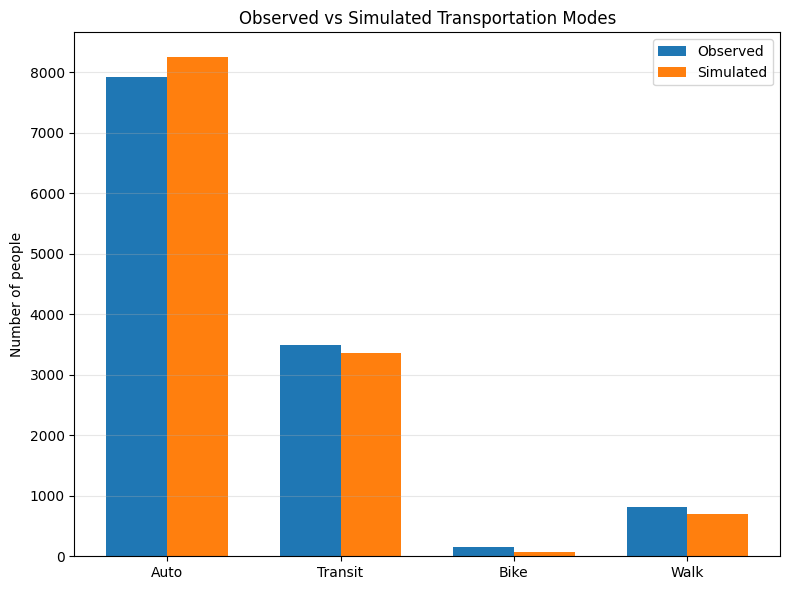


Optimization finished

Best MSE:
0.008788916668260732

Optimized coefficients:
[-1.05035186 -0.2062521  -0.18398634  0.80595838 -0.80076681 -0.7203347
 -0.80543335 -0.79946397  1.45868428 -0.34613331  1.07807868  1.26250856
 -1.04198921  0.11331991  1.12267195 -1.3993567   0.75912081 -0.26033004
  1.22846565 -1.15549441  0.34219242  0.8931017   0.04368939  0.87112941
 -0.89863922 -1.22656613 -1.166217   -0.08256626  0.41052682 -0.77746251
 -0.33880909  0.47879197  2.89170345  0.82624867 -3.89506936]


In [12]:
mse_history = []
beta_history = []


def objective(trial):


    Sugg_betas = np.array([

    # =========================================================
    # AUTO
    # =========================================================

    trial.suggest_float("β1", -1.40, -0.90),
    trial.suggest_float("β2", -0.30,  0.05),
    trial.suggest_float("β3", -0.55, -0.15),

    trial.suggest_float("β4",  0.65,  1.15),
    trial.suggest_float("β5", -1.00, -0.55),
    trial.suggest_float("β6", -0.90, -0.45),

    trial.suggest_float("β7", -0.90, -0.45),


    # =========================================================
    # TRANSIT
    # =========================================================

    trial.suggest_float("β8", -1.20, -0.75),
    trial.suggest_float("β9",  1.15,  1.60),
    trial.suggest_float("β10", -0.65, -0.20),

    trial.suggest_float("β11",  0.90,  1.35),
    trial.suggest_float("β12",  1.10,  1.50),
    trial.suggest_float("β13", -1.10, -0.65),

    trial.suggest_float("β14",  0.10,  0.55),
    trial.suggest_float("β15",  0.80,  1.30),


    # =========================================================
    # BIKE
    # =========================================================

    trial.suggest_float("β16", -1.65, -1.20),
    trial.suggest_float("β17",  0.35,  0.85),
    trial.suggest_float("β18", -0.55, -0.05),

    trial.suggest_float("β19",  1.10,  1.50),
    trial.suggest_float("β20", -1.50, -1.15),
    trial.suggest_float("β21",  0.15,  0.60),

    trial.suggest_float("β22",  0.65,  1.10),
    trial.suggest_float("β23", -0.30,  0.20),
    trial.suggest_float("β24",  0.60,  1.10),


    # =========================================================
    # WALK
    # =========================================================

    trial.suggest_float("β25", -0.90, -0.45),
    trial.suggest_float("β26", -1.55, -1.10),
    trial.suggest_float("β27", -1.20, -0.75),

    trial.suggest_float("β28", -0.10,  0.35),
    trial.suggest_float("β29",  0.20,  0.65),
    trial.suggest_float("β30", -0.90, -0.50),

    trial.suggest_float("β31", -0.75, -0.30),


    # =========================================================
    # PEER EFFECTS
    # =========================================================

    trial.suggest_float("γ_bike", 0.45, 1.10),


    # =========================================================
    # ASCs
    # WALK = REFERENCE ALTERNATIVE
    # =========================================================

    trial.suggest_float("ASC_auto", 1.80, 2.90),

    trial.suggest_float("ASC_transit", 0.40, 1.80),

    trial.suggest_float("ASC_bike", -4.00, -2.50)

])



    # Run calibration
    mse = calibration_error(betas = Sugg_betas,model = Transport_model,n_steps=5,save_results=False)


    mse_history.append(mse)
    beta_history.append(Sugg_betas.copy())


    print("\n-----------------------------")
    print(f"Trial: {trial.number}")
    print(f"MSE: {mse:.6f}")

    print("Betas:")
    print(Sugg_betas)


    return mse


# ============================================================
# Run Optuna
# ============================================================

study = optuna.create_study(direction="minimize",sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective,n_trials=100)


# ============================================================
# Extract best parameters
# ============================================================

best_params = study.best_params


optimized_betas = np.array([

    # Auto
    best_params["β1"],
    best_params["β2"],
    best_params["β3"],
    best_params["β4"],
    best_params["β5"],
    best_params["β6"],
    best_params["β7"],


    # Transit
    best_params["β8"],
    best_params["β9"],
    best_params["β10"],
    best_params["β11"],
    best_params["β12"],
    best_params["β13"],
    best_params["β14"],
    best_params["β15"],


    # Bike
    best_params["β16"],
    best_params["β17"],
    best_params["β18"],
    best_params["β19"],
    best_params["β20"],
    best_params["β21"],
    best_params["β22"],
    best_params["β23"],
    best_params["β24"],


    # Walk
    best_params["β25"],
    best_params["β26"],
    best_params["β27"],
    best_params["β28"],
    best_params["β29"],
    best_params["β30"],
    best_params["β31"],


    # Social interaction
    best_params["γ_bike"],

    # ASCs
    best_params["ASC_auto"],
    best_params["ASC_transit"],
    best_params["ASC_bike"]
])


#  CHECK CONVERGENCE OF TRANSPORTATION MODE CHOICES
Transport_model.reset_trial_state()
Transport_model.betas = optimized_betas

previous_modes = None

for step in range(5):

    Transport_model.model_step()

    current_modes = np.array([a.mode_choice for a in Transport_model.agent_list], dtype=object)

    if previous_modes is not None:
        changed = np.mean(current_modes != previous_modes)
        print(f"\nStep {step + 1}: " f"{changed * 100:.2f}% of agents changed mode")

    previous_modes = current_modes.copy()


# FINAL CALIBRATION WITH OPTIMIZED PARAMETERS
best_mse = calibration_error(betas = optimized_betas,model =Transport_model,n_steps=5,save_results=True)


print("\n==============================")
print("Optimization finished")
print("==============================")

print("\nBest MSE:")
print(study.best_value)

print("\nOptimized coefficients:")
print(optimized_betas)


# ============================================================
# Save coefficients
# ============================================================

np.save(os.path.join(data_path, "Betas_HighComplexity.npy"),optimized_betas)

#Randomly changing agents' residential locations and workplaces


========== BASELINE SIMULATION ==========


Agents activation: 100%|██████████| 12372/12372 [02:27<00:00, 84.12it/s]




Agents without peers: 0 out of 12372
[1/4] Computing car travel times...
Done (98.5 s)
[2/4] Computing walking travel times...
Done (131.6 s)
[3/4] Computing STM travel times...
Done (83.2 s)
[4/4] Computing BIKE travel times...
Done (140.8 s)

========== SIMULATION STEP 1 ==========

========== SIMULATION STEP 2 ==========

========== SIMULATION STEP 3 ==========

========== SIMULATION STEP 4 ==========

========== SIMULATION STEP 5 ==========

Execution time for 5 steps: 11.679 seconds

Baseline counts: [8193 3333   79  767]


========== 10% RELOCATION SCENARIO ==========


Agents activation: 100%|██████████| 12372/12372 [02:26<00:00, 84.48it/s]




Agents without peers: 0 out of 12372
[1/4] Computing car travel times...
Done (98.9 s)
[2/4] Computing walking travel times...
Done (133.2 s)
[3/4] Computing STM travel times...
Done (95.7 s)
[4/4] Computing BIKE travel times...
Done (142.1 s)

========== SIMULATION STEP 1 ==========
[1/4] Computing car travel times...
Done (11.1 s)
[2/4] Computing walking travel times...
Done (14.5 s)
[3/4] Computing STM travel times...
Done (9.9 s)
[4/4] Computing BIKE travel times...
Done (15.5 s)
Agents relocated in step 1: 1237

========== SIMULATION STEP 2 ==========
[1/4] Computing car travel times...
Done (10.9 s)
[2/4] Computing walking travel times...
Done (14.2 s)
[3/4] Computing STM travel times...
Done (9.7 s)
[4/4] Computing BIKE travel times...
Done (14.9 s)
Agents relocated in step 2: 1237

========== SIMULATION STEP 3 ==========
[1/4] Computing car travel times...
Done (10.0 s)
[2/4] Computing walking travel times...
Done (14.2 s)
[3/4] Computing STM travel times...
Done (10.5 s)
[4/

Agents activation: 100%|██████████| 12372/12372 [02:31<00:00, 81.83it/s]




Agents without peers: 0 out of 12372
[1/4] Computing car travel times...
Done (98.4 s)
[2/4] Computing walking travel times...
Done (133.8 s)
[3/4] Computing STM travel times...
Done (84.8 s)
[4/4] Computing BIKE travel times...
Done (141.7 s)

========== SIMULATION STEP 1 ==========
[1/4] Computing car travel times...
Done (20.3 s)
[2/4] Computing walking travel times...
Done (27.5 s)
[3/4] Computing STM travel times...
Done (19.2 s)
[4/4] Computing BIKE travel times...
Done (29.0 s)
Agents relocated in step 1: 2474

========== SIMULATION STEP 2 ==========
[1/4] Computing car travel times...
Done (19.2 s)
[2/4] Computing walking travel times...
Done (26.3 s)
[3/4] Computing STM travel times...
Done (16.8 s)
[4/4] Computing BIKE travel times...
Done (27.2 s)
Agents relocated in step 2: 2474

========== SIMULATION STEP 3 ==========
[1/4] Computing car travel times...
Done (19.5 s)
[2/4] Computing walking travel times...
Done (27.5 s)
[3/4] Computing STM travel times...
Done (17.2 s)
[

Agents activation: 100%|██████████| 12372/12372 [02:35<00:00, 79.81it/s]




Agents without peers: 0 out of 12372
[1/4] Computing car travel times...
Done (99.1 s)
[2/4] Computing walking travel times...
Done (132.6 s)
[3/4] Computing STM travel times...
Done (81.1 s)
[4/4] Computing BIKE travel times...
Done (140.0 s)

========== SIMULATION STEP 1 ==========
[1/4] Computing car travel times...
Done (30.0 s)
[2/4] Computing walking travel times...
Done (41.9 s)
[3/4] Computing STM travel times...
Done (26.3 s)
[4/4] Computing BIKE travel times...
Done (43.0 s)
Agents relocated in step 1: 3711

========== SIMULATION STEP 2 ==========
[1/4] Computing car travel times...
Done (29.9 s)
[2/4] Computing walking travel times...
Done (39.7 s)
[3/4] Computing STM travel times...
Done (25.1 s)
[4/4] Computing BIKE travel times...
Done (41.1 s)
Agents relocated in step 2: 3711

========== SIMULATION STEP 3 ==========
[1/4] Computing car travel times...
Done (29.6 s)
[2/4] Computing walking travel times...
Done (39.3 s)
[3/4] Computing STM travel times...
Done (25.6 s)
[

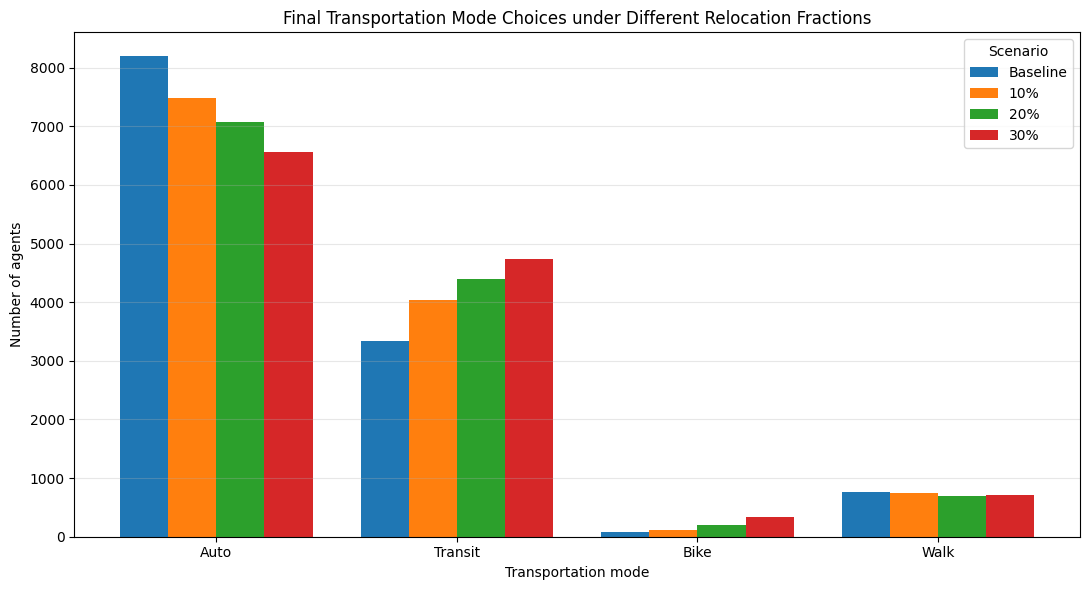

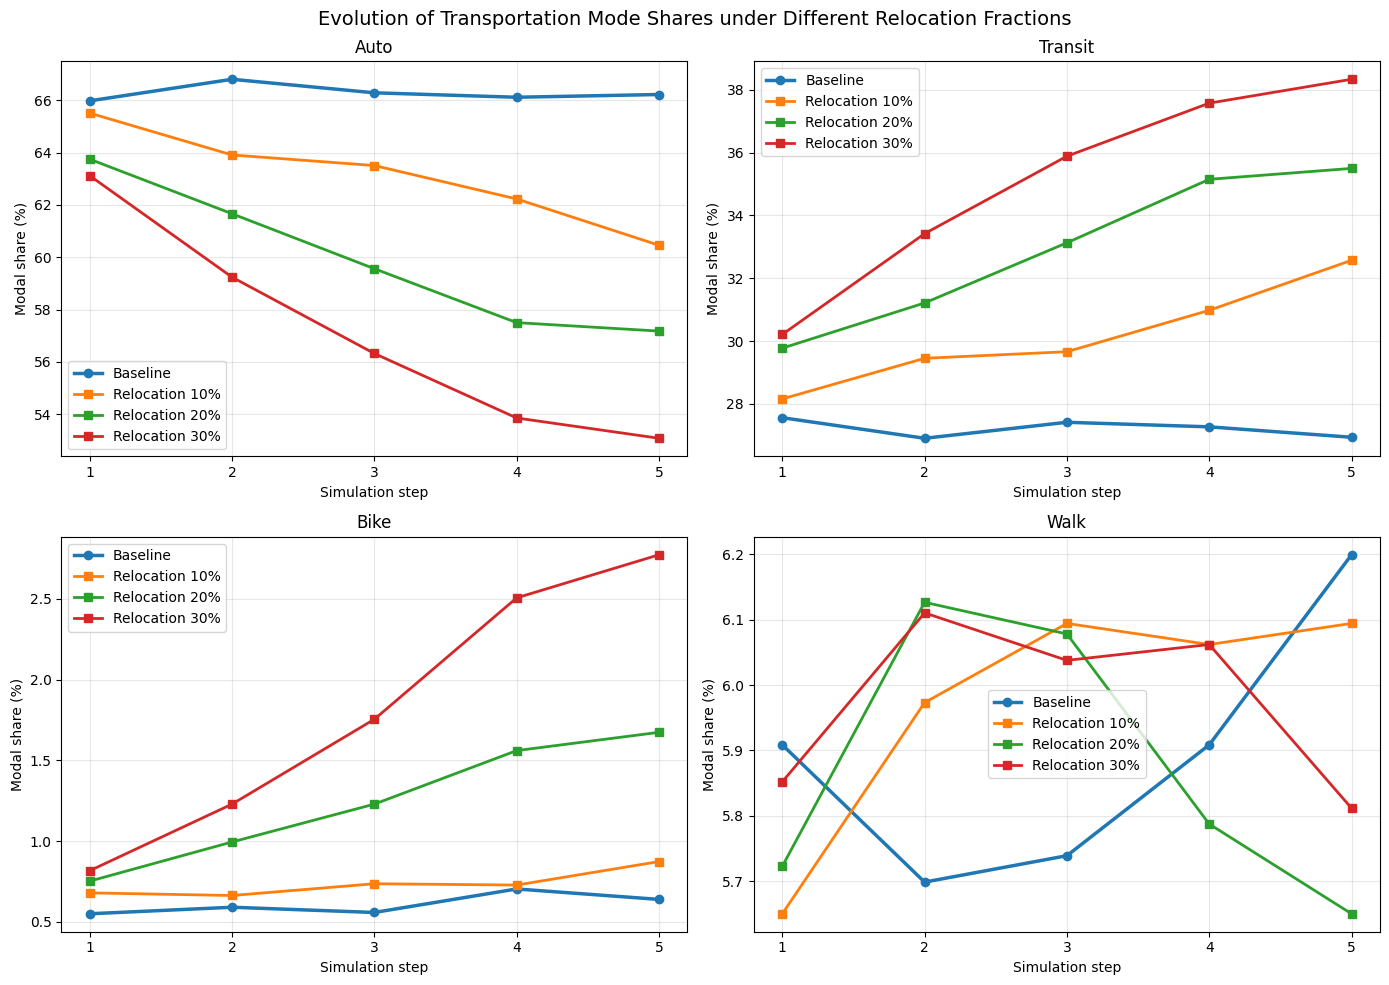

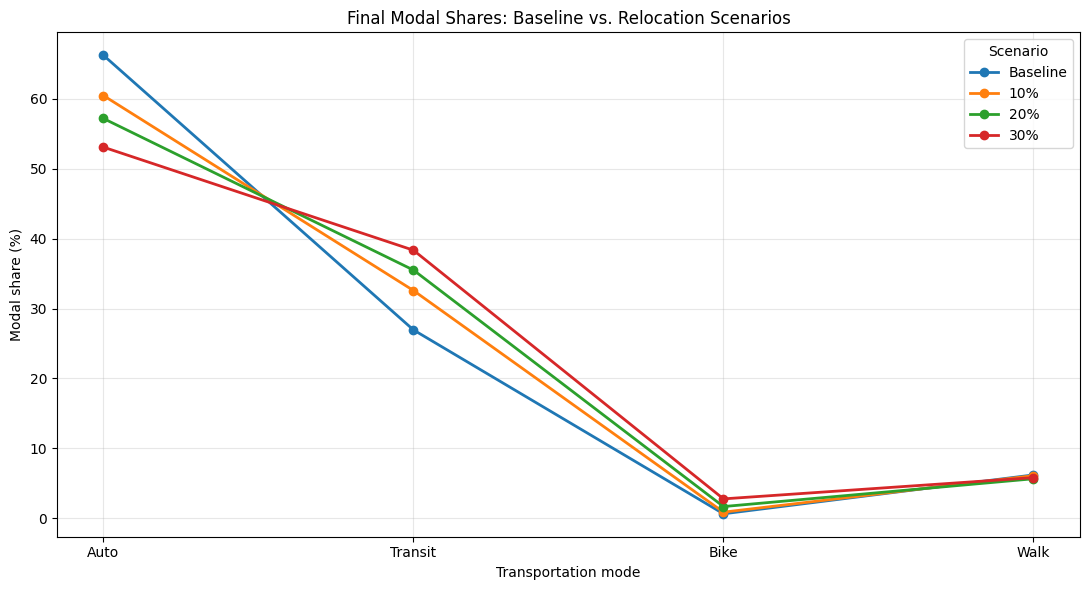

In [14]:
# LOAD OPTIMIZED COEFFICIENTS AND DEFINE EXPERIMENTS

Optimized_betas = np.load(os.path.join(data_path, "Betas_HighComplexity.npy"))

modes = ["auto", "transit", "bike", "walk"]
mode_labels = ["Auto", "Transit", "Bike", "Walk"]

n_steps = 5

relocation_fractions = [0.10, 0.20, 0.30]

# Use identical seeds to create comparable initial conditions
initialization_seed = 42
simulation_seed = 123


# INITIALIZE AN INDEPENDENT TRANSPORT MODEL

def initialize_transport_model(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    model = TransportModel(
        n_rep=50,
        DA_MTL=montreal_da,
        Res=residential,
        Net_car=netx_car,
        Net_walk=netx_walk,
        Net_bike=netx_bike,
        Net_transit=netx_transit,
        Wrk_N=workplaces,
        STM_N=stm,
        bikelanes=Bikelanes
    )

    model.betas = Optimized_betas.copy()

    return model


# RELOCATE AGENTS

def relocate_agents(model,relocation_fraction=0.30,relocation_rng=None):

    if relocation_rng is None:
        relocation_rng = random.Random(42)

    agents = model.agent_list
    n_agents = len(agents)

    sample_size = int(relocation_fraction * n_agents)

    # Randomly select agents using a separate random generator
    selected_indices = relocation_rng.sample(range(n_agents),sample_size)

    selected_agents = [agents[i] for i in selected_indices]

    residential_ids = model.residential["res_id"].unique()

    # Preserve the model's random-number streams so that relocation operations do not alter the random sequence used by the subsequent model step.
    python_state = random.getstate()
    numpy_state = np.random.get_state()

    try:

        for agent in selected_agents:

            old_res_id = agent.res_id

            # Select a different residential location
            possible_locations = residential_ids[residential_ids != old_res_id]

            if len(possible_locations) > 0:
                new_res_id = relocation_rng.choice(possible_locations)
                agent.res_id = new_res_id

            # Reset workplace information
            agent.work_id = None
            agent.work_x = np.nan
            agent.work_y = np.nan

            agent.workplace_node_network = None
            agent.work_stm_node_network = None

            # Assign new residential and workplace nodes
            agent.assign_nodes()

        # Update local population density
        model.assign_local_population_density()

        # Update transit stop density for relocated agents
        model.assign_transit_stop_density(selected_agents)

        # Recalculate travel times for relocated agents
        model.compute_all_travel_times(selected_agents)

    finally:

        # Restore random-number streams
        random.setstate(python_state)
        np.random.set_state(numpy_state)

    return selected_indices


# RUN TRANSPORT SIMULATION

def run_transport_simulation(model,betas,n_steps=5,relocate=False,relocation_fraction=0.30,relocation_seed=42,simulation_seed=123):

    # Reset model state
    model.reset_trial_state()

    model.betas = betas.copy()

    # Reinitialize simulation random-number streams
    random.seed(simulation_seed)
    np.random.seed(simulation_seed)

    # Independent random generator for relocation sampling
    relocation_rng = random.Random(relocation_seed)

    relocation_history = []
    mode_history = []

    start = time.perf_counter()

    for step in range(n_steps):

        print(f"\n========== SIMULATION STEP {step + 1} ==========")

        # Relocate agents at every step
        if relocate:
            selected_indices = relocate_agents(model,relocation_fraction=relocation_fraction,relocation_rng=relocation_rng)
            relocation_history.append(selected_indices)
            print(f"Agents relocated in step {step + 1}: "f"{len(selected_indices)}")

        # Execute model step
        model.model_step()

        # Record mode choices
        current_choices = np.array([a.mode_choice for a in model.agent_list],dtype=object)
        mode_history.append(current_choices.copy())

    elapsed = time.perf_counter() - start

    print(f"\nExecution time for {n_steps} steps: "f"{elapsed:.3f} seconds")

    final_choices = mode_history[-1]

    return (final_choices,relocation_history,mode_history)


# BASELINE SIMULATION (NO RELOCATION)

print("\n========== BASELINE SIMULATION ==========")

Baseline_model = initialize_transport_model(seed=initialization_seed)

baseline_choices, _, baseline_mode_history = (run_transport_simulation(model=Baseline_model,betas=Optimized_betas,n_steps=n_steps,relocate=False,simulation_seed=simulation_seed))

n_agents = len(Baseline_model.agent_list)

baseline_counts = np.array([np.sum(baseline_choices == mode)for mode in modes])
print("\nBaseline counts:", baseline_counts)


# RUN THREE RELOCATION SCENARIOS

scenario_results = {}

for fraction in relocation_fractions:

    percentage = int(fraction * 100)

    print(f"\n\n========== "f"{percentage}% RELOCATION SCENARIO ==========")

    # Create a completely independent model instance
    scenario_model = initialize_transport_model(seed=initialization_seed)

    (final_choices,relocation_history,mode_history) = run_transport_simulation(model=scenario_model,betas=Optimized_betas,n_steps=n_steps,relocate=True,
                                                                               relocation_fraction=fraction,relocation_seed=simulation_seed,simulation_seed=simulation_seed)

    # Final modal counts
    final_counts = np.array([np.sum(final_choices == mode)for mode in modes])

    # Counts at every simulation step
    step_counts = np.array([[np.sum(choices == mode)for mode in modes]for choices in mode_history])

    # Modal shares at every step
    step_shares = (step_counts / n_agents) * 100

    # Unique agents relocated across all steps
    unique_relocated = set(i for selected_indices in relocation_history for i in selected_indices)

    # Store results
    scenario_results[f"{percentage}%"] = {

        "model": scenario_model,
        "final_choices": final_choices,
        "final_counts": final_counts,
        "relocation_history": relocation_history,
        "mode_history": mode_history,
        "step_counts": step_counts,
        "step_shares": step_shares,
        "unique_relocated": unique_relocated
    }

    print("\nFinal modal counts:", final_counts)
    print("Unique agents relocated:",len(unique_relocated))
    print("Percentage of unique agents relocated:",round(len(unique_relocated) / n_agents * 100,2),"%")


# MODAL SHARES AT EVERY STEP

steps = np.arange(1, n_steps + 1)

baseline_step_counts = np.array([[np.sum(choices == mode)for mode in modes] for choices in baseline_mode_history])

baseline_step_shares = (baseline_step_counts / n_agents) * 100


# Create a DataFrame for each scenario
baseline_shares_df = pd.DataFrame(baseline_step_shares,columns=mode_labels,index=steps)

baseline_shares_df.index.name = "Simulation step"
print("\n========== BASELINE MODAL SHARES (%) ==========")
print(baseline_shares_df.round(3))


for scenario_name, results in scenario_results.items():

    shares_df = pd.DataFrame(results["step_shares"],columns=mode_labels,index=steps)

    shares_df.index.name = "Simulation step"
    print(f"\n========== {scenario_name} "f"RELOCATION MODAL SHARES (%) ==========")
    print(shares_df.round(3))


# FINAL MODAL SHARE COMPARISON
comparison_data = []

# Baseline
comparison_data.append({"Scenario": "Baseline",**{mode_labels[i]: baseline_counts[i] / n_agents * 100 for i in range(len(modes))}})

# Relocation scenarios
for scenario_name, results in scenario_results.items():

    counts = results["final_counts"]
    comparison_data.append({"Scenario": scenario_name,**{mode_labels[i]: counts[i] / n_agents * 100 for i in range(len(modes))}})


final_share_comparison_df = pd.DataFrame(comparison_data)

print("\n========== FINAL MODAL SHARE COMPARISON (%) ==========")

print(final_share_comparison_df.round(3).to_string(index=False))


# FINAL MODAL COUNT COMPARISON

count_data = []

count_data.append({"Scenario": "Baseline",**{mode_labels[i]: baseline_counts[i] for i in range(len(modes))}})

for scenario_name, results in scenario_results.items():

    counts = results["final_counts"]
    count_data.append({"Scenario": scenario_name,**{mode_labels[i]: counts[i] for i in range(len(modes))}})


final_count_comparison_df = pd.DataFrame(count_data)

print("\n========== FINAL MODAL COUNT COMPARISON ==========")

print(final_count_comparison_df.to_string(index=False))


# RELOCATION SUMMARY

print("\n========== RELOCATION SUMMARY ==========")

for scenario_name, results in scenario_results.items():

    relocation_history = results["relocation_history"]
    unique_relocated = results["unique_relocated"]

    print(f"\n{scenario_name} relocation:")

    for step, selected_indices in enumerate(relocation_history):
        print(f"Step {step + 1}: "f"{len(selected_indices)} agents relocated")

    print("Unique agents relocated:",len(unique_relocated))
    print("Percentage of unique agents relocated:",round(len(unique_relocated) / n_agents * 100,2),"%")


# ============================================================
# 11. MODE TRANSITIONS: BASELINE VS EACH SCENARIO
# ============================================================

for scenario_name, results in scenario_results.items():

    final_choices = results["final_choices"]

    transition_df = pd.crosstab(
        pd.Categorical(
            baseline_choices,
            categories=modes
        ),
        pd.Categorical(
            final_choices,
            categories=modes
        ),
        rownames=["Before"],
        colnames=["After"],
        dropna=False
    )

    print(f"\n========== MODE TRANSITIONS: "f"BASELINE VS {scenario_name} ==========")

    print(transition_df)

    changed_modes = baseline_choices != final_choices

    print("\nAgents changing transportation mode:",changed_modes.sum())

    print("Percentage changing transportation mode:",round(changed_modes.mean() * 100, 2),"%")

    # Relocated versus non-relocated agents
    relocated_mask = np.zeros(n_agents, dtype=bool)

    relocated_mask[list(results["unique_relocated"])] = True

    relocated_changed = np.sum(changed_modes & relocated_mask)

    non_relocated_changed = np.sum(changed_modes & ~relocated_mask)

    print("Relocated agents changing mode:",relocated_changed)

    if relocated_mask.sum() > 0:
        print("Percentage of relocated agents changing mode:",round(relocated_changed / relocated_mask.sum() * 100,2),"%")
    print("Non-relocated agents changing mode:",non_relocated_changed)
    if (~relocated_mask).sum() > 0:
        print("Percentage of non-relocated agents changing mode:",round(non_relocated_changed /(~relocated_mask).sum() * 100,2),"%")


# PLOT 1: FINAL MODAL COUNTS

scenario_names = ["Baseline","10%","20%","30%"]

count_arrays = [baseline_counts] + [scenario_results[name]["final_counts"]for name in ["10%", "20%", "30%"]]

x = np.arange(len(modes))

bar_width = 0.20

plt.figure(figsize=(11, 6))

for i, (scenario_name, counts) in enumerate(zip(scenario_names, count_arrays)):
    offset = (i - 1.5) * bar_width
    plt.bar(x + offset,counts,width=bar_width,label=scenario_name)

plt.xticks(x, mode_labels)
plt.ylabel("Number of agents")
plt.xlabel("Transportation mode")
plt.title("Final Transportation Mode Choices ""under Different Relocation Fractions")

plt.grid(axis="y",alpha=0.3)

plt.legend(title="Scenario")

plt.tight_layout()
plt.show()


# PLOT 2: MODAL SHARE EVOLUTION (2 x 2)

fig, axes = plt.subplots(2,2,figsize=(14, 10))

for i, ax in enumerate(axes.flatten()):

    # Baseline
    ax.plot(steps,baseline_step_shares[:, i], marker="o",linewidth=2.5,label="Baseline")

    # Relocation scenarios
    for scenario_name in ["10%", "20%", "30%"]:
        scenario_shares = scenario_results[scenario_name]["step_shares"]
        ax.plot(steps, scenario_shares[:, i],marker="s",linewidth=2,label=f"Relocation {scenario_name}")

    ax.set_title(mode_labels[i])
    ax.set_xlabel("Simulation step")
    ax.set_ylabel("Modal share (%)")
    ax.set_xticks(steps)
    ax.grid(alpha=0.3)
    ax.legend()


fig.suptitle("Evolution of Transportation Mode Shares ""under Different Relocation Fractions",fontsize=14)

plt.tight_layout()
plt.show()


# PLOT 3: FINAL MODAL SHARES

plt.figure(figsize=(11, 6))

for scenario_name in scenario_names:

    if scenario_name == "Baseline":
        shares = (baseline_counts / n_agents) * 100
    else:
        shares = (scenario_results[scenario_name]["final_counts"]/ n_agents) * 100

    plt.plot(mode_labels,shares, marker="o",linewidth=2,label=scenario_name)

plt.ylabel("Modal share (%)")
plt.xlabel("Transportation mode")
plt.title("Final Modal Shares: Baseline vs. Relocation Scenarios")
plt.grid(alpha=0.3)
plt.legend(title="Scenario")
plt.tight_layout()
plt.show()


# The 30% relocation scenario standalone


========== BASELINE SIMULATION ==========

========== SIMULATION STEP 1 ==========

========== SIMULATION STEP 2 ==========

========== SIMULATION STEP 3 ==========

========== SIMULATION STEP 4 ==========

========== SIMULATION STEP 5 ==========

Execution time for 5 steps: 9.236 seconds

Baseline counts: [8204 3072   58 1038]

========== POST-RELOCATION SIMULATION ==========

========== SIMULATION STEP 1 ==========
[1/4] Computing car travel times...
Done (30.4 s)
[2/4] Computing walking travel times...
Done (44.9 s)
[3/4] Computing STM travel times...
Done (26.6 s)
[4/4] Computing BIKE travel times...
Done (47.2 s)
Agents relocated in step 1: 3711

========== SIMULATION STEP 2 ==========
[1/4] Computing car travel times...
Done (32.1 s)
[2/4] Computing walking travel times...
Done (45.6 s)
[3/4] Computing STM travel times...
Done (26.6 s)
[4/4] Computing BIKE travel times...
Done (45.6 s)
Agents relocated in step 2: 3711

========== SIMULATION STEP 3 ==========
[1/4] Computing car 

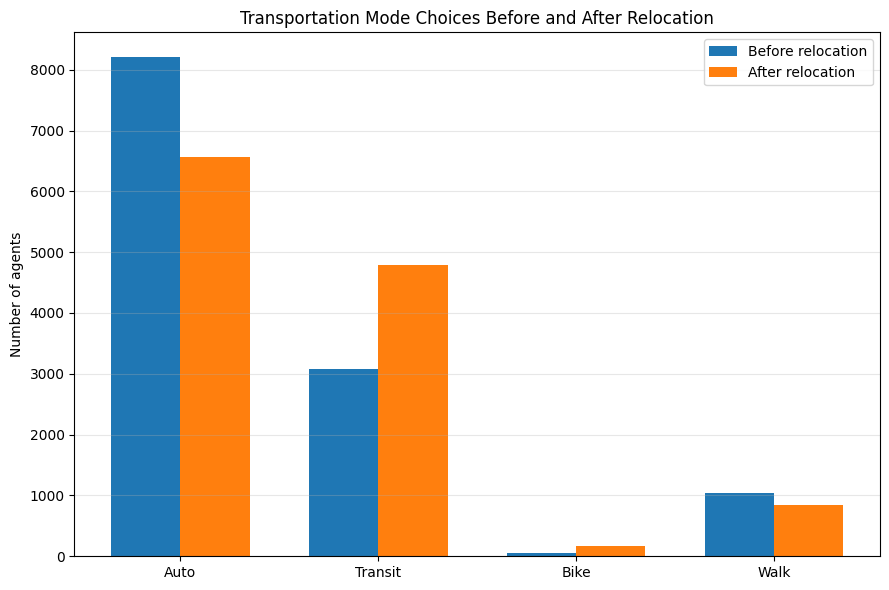

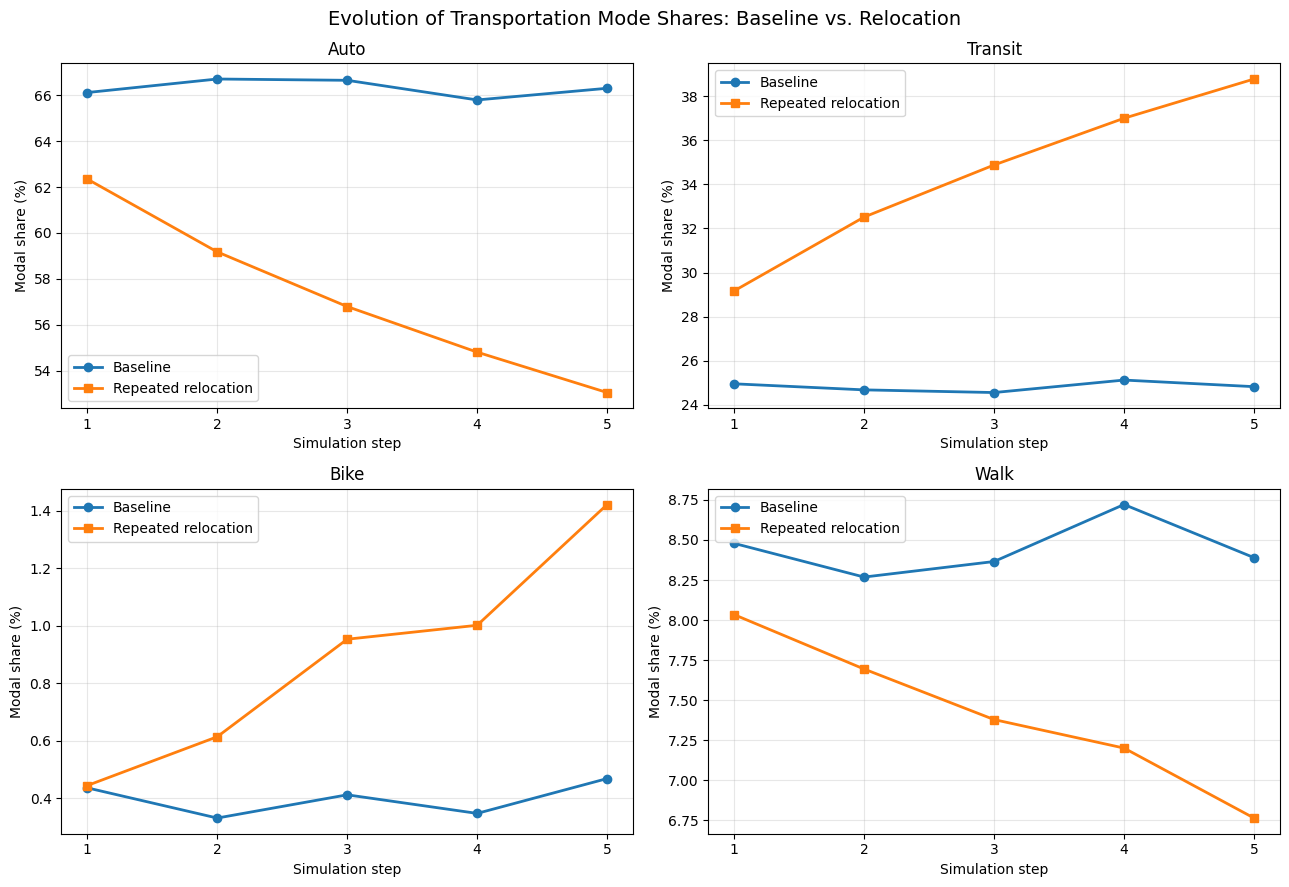

In [67]:
# LOAD OPTIMIZED COEFFICIENTS
Optimized_betas = np.load(os.path.join(data_path, "Betas_HighComplexity.npy"))
Transport_model.betas = Optimized_betas

agents = Transport_model.agent_list
n_agents = len(agents)

modes = ["auto", "transit", "bike", "walk"]
mode_labels = ["Auto", "Transit", "Bike", "Walk"]

n_steps = 5
relocation_fraction = 0.30


def relocate_agents(model, relocation_fraction=0.30):

    agents = model.agent_list
    n_agents = len(agents)

    # Randomly select agents for relocation
    sample_size = int(relocation_fraction * n_agents)

    selected_indices = random.sample(range(n_agents),sample_size)
    selected_agents = [agents[i] for i in selected_indices]

    # Valid residential locations
    residential_ids = model.residential["res_id"].unique()

    # Change residential and workplace locations
    for agent in selected_agents:

        old_res_id = agent.res_id

        # Select a different residential location
        possible_locations = residential_ids[residential_ids != old_res_id]

        if len(possible_locations) > 0:
            new_res_id = random.choice(possible_locations)
            agent.res_id = new_res_id

        # Reset workplace information
        agent.work_id = None
        agent.work_x = np.nan
        agent.work_y = np.nan

        agent.workplace_node_network = None
        agent.work_stm_node_network = None

        # Assign new residential and workplace nodes
        agent.assign_nodes()

    # Update local population density
    model.assign_local_population_density()
    model.assign_transit_stop_density(selected_agents)

    # Recalculate travel times
    model.compute_all_travel_times(selected_agents)

    return selected_indices


# Run simulation
def run_transport_simulation(model,betas,n_steps=5,relocate=False,relocation_fraction=0.30):
    model.reset_trial_state()
    model.betas = betas

    relocation_history = []
    mode_history = []

    start = time.perf_counter()

    for step in range(n_steps):

        print(f"\n========== SIMULATION STEP {step + 1} ==========")

        # Relocate agents at every step

        if relocate:
          selected_indices = relocate_agents(model,relocation_fraction=relocation_fraction)
          relocation_history.append(selected_indices)
          print(f"Agents relocated in step {step + 1}: "f"{len(selected_indices)}")

        # Execute model step
        model.model_step()

        # Record mode choices after each step
        current_choices = np.array([a.mode_choice for a in model.agent_list],dtype=object)
        mode_history.append(current_choices.copy())

    elapsed = time.perf_counter() - start

    print(f"\nExecution time for {n_steps} steps: "f"{elapsed:.3f} seconds")

    final_choices = mode_history[-1]

    return (final_choices,relocation_history,mode_history)


# Baseline simulation: without relocation

print("\n========== BASELINE SIMULATION ==========")

baseline_choices, _, baseline_mode_history = run_transport_simulation(Transport_model,Optimized_betas,n_steps=n_steps,relocate=False)
baseline_counts = np.array([np.sum(baseline_choices == mode) for mode in modes])
print("\nBaseline counts:", baseline_counts)


# Post-relocation simulation

print("\n========== POST-RELOCATION SIMULATION ==========")

new_choices, relocation_history, relocation_mode_history = run_transport_simulation(Transport_model,Optimized_betas,n_steps=n_steps,relocate=True,relocation_fraction=relocation_fraction)
new_counts = np.array([np.sum(new_choices == mode)for mode in modes])
print("\nPost-relocation counts:", new_counts)


# Calculate mode counts at every step
baseline_step_counts = np.array([[np.sum(choices == mode)for mode in modes] for choices in baseline_mode_history])
relocation_step_counts = np.array([[np.sum(choices == mode)for mode in modes] for choices in relocation_mode_history])


# Calculate modal shares at every step

baseline_step_shares = (baseline_step_counts / n_agents) * 100
relocation_step_shares = (relocation_step_counts / n_agents) * 100


# Create modal share df
steps = np.arange(1, n_steps + 1)

baseline_shares_df = pd.DataFrame(baseline_step_shares,columns=mode_labels,index=steps)
baseline_shares_df.index.name = "Simulation step"

relocation_shares_df = pd.DataFrame(relocation_step_shares,columns=mode_labels,index=steps)
relocation_shares_df.index.name = "Simulation step"

print("\n========== BASELINE MODAL SHARES (%) ==========")
print(baseline_shares_df.round(3))

print("\n========== RELOCATION MODAL SHARES (%) ==========")
print(relocation_shares_df.round(3))


# Compare before and after relocation

print("\n========== FINAL MODAL SHARE COMPARISON ==========")

comparison_df = pd.DataFrame({
    "Mode": mode_labels,
    "Before": baseline_counts,
    "After": new_counts,
    "Difference": new_counts - baseline_counts,
    "Before_share": baseline_counts / n_agents,
    "After_share": new_counts / n_agents})

comparison_df["Change_pp"] = (comparison_df["After_share"]- comparison_df["Before_share"]) * 100
print(comparison_df.round(3))

#  Relocation summary

print("\n========== RELOCATION SUMMARY ==========")

for step, selected_indices in enumerate(relocation_history):
  print(f"Step {step + 1}: "f"{len(selected_indices)} agents relocated")

# Unique agents relocated across all five steps
unique_relocated = set(i for selected_indices in relocation_history for i in selected_indices)

print("\nUnique agents relocated across five steps:",len(unique_relocated))
print("Percentage of unique agents relocated:",round(len(unique_relocated) / n_agents * 100, 2),"%")


# Individual transportation mode transitions

transition_df = pd.crosstab(pd.Categorical(baseline_choices,categories=modes),pd.Categorical(new_choices,categories=modes),rownames=["Before"],colnames=["After"],dropna=False)

print("\n========== TRANSPORTATION MODE TRANSITIONS ==========")
print(transition_df)


# Agents changing transportation mode
changed_modes = baseline_choices != new_choices
print("\nAgents changing transportation mode:",changed_modes.sum())
print("Percentage changing transportation mode:",round(changed_modes.mean() * 100, 2),"%")

# Relocated Vs non-relocated agents
relocated_mask = np.zeros(n_agents, dtype=bool)
relocated_mask[list(unique_relocated)] = True
relocated_changed = np.sum(changed_modes & relocated_mask)
non_relocated_changed = np.sum(changed_modes & ~relocated_mask)

print("\nRelocated agents changing mode:",relocated_changed)

if relocated_mask.sum() > 0:
    print("Percentage of relocated agents changing mode:",round( relocated_changed / relocated_mask.sum() * 100,2),"%")

print("\nNon-relocated agents changing mode:",non_relocated_changed)

if (~relocated_mask).sum() > 0:
    print("Percentage of non-relocated agents changing mode:",round(non_relocated_changed / (~relocated_mask).sum() * 100,2),"%")


# Plots
x = np.arange(len(modes))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(x - width / 2,baseline_counts,width,label="Before relocation")
plt.bar(x + width / 2,new_counts,width,label="After relocation")

plt.xticks(x, mode_labels)
plt.ylabel("Number of agents")

plt.title("Transportation Mode Choices Before and After Relocation")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2,2,figsize=(13, 9))

for i, ax in enumerate(axes.flatten()):

    ax.plot(steps,baseline_step_shares[:, i],marker="o",linewidth=2,label="Baseline")
    ax.plot(steps,relocation_step_shares[:, i],marker="s",linewidth=2,label="Repeated relocation")

    ax.set_title(mode_labels[i])
    ax.set_xlabel("Simulation step")
    ax.set_ylabel("Modal share (%)")

    ax.set_xticks(steps)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Evolution of Transportation Mode Shares: Baseline vs. Relocation",fontsize=14)
plt.tight_layout()
plt.show()
